# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** ALFONSO sOOTS MALDONADO 
**Grupo:** 511  **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la cantidad de pasajeros y la distancia recorrida?**

Se pueden identificar los siguientes tipos de viajes:

**Viajes cortos individuales**: un pasajero, con una distancia media de 1.36 millas.

**Viajes cortos de dos pasajeros**: dos pasajeros, con una distancia media de 1.58 millas.

**Viajes cortos en grupos grandes**: alrededor de 4 pasajeros, con una distancia media de 1.97 millas.

**Viajes largos individuales**: un pasajero, con una distancia media de 9.54 millas.

**Viajes largos con varios pasajeros**: alrededor de 2 a 3 pasajeros, con una distancia media de 13.14 millas.



Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`passenger_count`** y **`trip_distance`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_B_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_B/
└── notebooks/
    └── Examen_B_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
#Importar librerias
import pandas as pd
import numpy as np

In [2]:
# Cargar archivo
df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")


In [3]:
# Datos

#Primeras 5 filas
display(df.head())

#Dimensiones
print(df.shape)

#Nombres
print(df.columns.tolist())

#Tipos
print(df.dtypes)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


(2427612, 20)
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type             float64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
cbd_congestion_fee       float64
trip_duration  

In [4]:
#Resumen estadistico

print("\nResumen estadístico:")
display(df.describe())


Resumen estadístico:


,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2.427612e+06,2.415489e+06,2.415470e+06,2.415474e+06,2.415487e+06,2.415475e+06,2.415487e+06,2.415488e+06,2.415487e+06,2.415462e+06,2.415459e+06,2.415465e+06,2.415481e+06,2.415484e+06,2.415457e+06,2.415481e+06,2.415462e+06,2.415475e+06
mean,1.888167e+00,1.296144e+00,3.300702e+00,4.229419e+00,1.641392e+02,1.632236e+02,1.174306e+00,3.852567e+01,1.567837e+00,4.849912e-01,3.665195e+00,5.938668e-01,9.873437e-01,2.937731e+01,2.254823e+00,1.979527e-01,5.625318e-01,1.561446e+01
std,8.086844e-01,1.881923e+00,5.167909e+00,1.720220e+01,6.285386e+01,6.925613e+01,4.594154e-01,5.423764e+02,1.906552e+00,1.018682e-01,4.234050e+00,2.385704e+00,1.560490e-01,2.592570e+01,7.815658e-01,6.259005e-01,3.314852e-01,2.605773e+02
min,1.000000e+00,-5.000000e+00,-9.998763e+01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,-1.849600e+03,-7.500000e+00,-5.000000e-01,-9.000000e+01,-1.064600e+02,-1.000000e+00,-1.866890e+03,-2.500000e+00,-2.000000e+00,-7.500000e-01,-3.005175e+05
25%,2.000000e+00,1.000000e+00,9.900000e-01,1.000000e+00,1.320000e+02,1.130000e+02,1.000000e+00,9.300000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.638000e+01,2.500000e+00,0.000000e+00,7.500000e-01,7.283333e+00
50%,2.000000e+00,1.000000e+00,1.700000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.000000e+00,1.350000e+01,1.000000e+00,5.000000e-01,2.950000e+00,0.000000e+00,1.000000e+00,2.154000e+01,2.500000e+00,0.000000e+00,7.500000e-01,1.231667e+01
75%,2.000000e+00,1.000000e+00,3.360000e+00,1.000000e+00,2.320000e+02,2.340000e+02,1.000000e+00,2.190000e+01,2.500000e+00,5.000000e-01,4.560000e+00,0.000000e+00,1.000000e+00,3.145000e+01,2.500000e+00,0.000000e+00,7.500000e-01,2.011667e+01
max,7.000000e+00,1.000000e+02,1.686490e+03,9.900000e+01,2.650000e+02,2.650000e+02,4.000000e+00,1.999559e+04,2.325000e+01,1.150000e+01,4.444400e+02,6.167900e+02,1.000000e+00,5.530740e+03,2.750000e+00,2.700000e+01,7.500000e-01,8.373667e+03


In [5]:
print(df["payment_type"].unique())

[ 1.  2. nan  4.  3.]


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [6]:
df_limpio = df.copy()
print("Dimensiones antes de limpiar:", df_limpio.shape)


Dimensiones antes de limpiar: (2427612, 20)


In [7]:
#Nulos por columna
print(df_limpio.isnull().sum())

VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64


In [8]:
#Duplicados antes de limpiar
print(df_limpio.duplicated().sum())

11961


In [9]:
#Eliminar duplicados y filas con nulos 
df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()

In [10]:
df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0) &
    (df_limpio["passenger_count"] > 0) &
    (df_limpio["passenger_count"] < 100) &
    (df_limpio["fare_amount"] > 0) &
    (df_limpio["fare_amount"] < 10000) &
    (df_limpio["trip_duration"] > 0)
].copy()

In [11]:
# Resultados
print( df_limpio.shape)
print(len(df_limpio))




(2096600, 20)
2096600


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`passenger_count`** y **`trip_distance`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [12]:
#Filtros
df_cash = df_limpio[df_limpio["payment_type"] == 2.0].copy()

In [13]:
#Variables para kmeans
X = df_cash[["passenger_count", "trip_distance"]].copy()


In [14]:
#Cantidad de viajes 
print("Cantidad de viajes con pago en efectivo:", len(df_cash))


Cantidad de viajes con pago en efectivo: 282085


In [15]:
print("\nEstadísticas descriptivas:")
display(X.describe())


Estadísticas descriptivas:


,passenger_count,trip_distance
count,282085.000000,282085.000000
mean,1.343882,3.842165
std,0.759067,6.214391
min,1.000000,0.010000
25%,1.000000,0.920000
50%,1.000000,1.700000
75%,1.000000,4.370000
max,6.000000,1686.490000


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [16]:
X_log = np.log1p(X)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

#Transformacion
X_escalado = pd.DataFrame(
    scaler.fit_transform(X_log),
    columns=X_log.columns,
    index=X_log.index
)

#Transformacion
print()
display(X_log.describe())

#Estandarizados
print()
display(X_escalado.describe())



,passenger_count,trip_distance
count,282085.000000,282085.000000
mean,0.814772,1.225454
std,0.250268,0.763298
min,0.693147,0.009950
25%,0.693147,0.652325
50%,0.693147,0.993252
75%,0.693147,1.680828
max,1.945910,7.430997


,passenger_count,trip_distance
count,2.820850e+05,2.820850e+05
mean,-2.651894e-16,2.095721e-16
std,1.000002e+00,1.000002e+00
min,-4.859776e-01,-1.592439e+00
25%,-4.859776e-01,-7.508596e-01
50%,-4.859776e-01,-3.042097e-01
75%,-4.859776e-01,5.965880e-01
max,4.519712e+00,8.129920e+00


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

In [17]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#Evaluar k

resultados = []

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = kmeans.fit_predict(X_escalado)

    inercia = kmeans.inertia_

    silueta = silhouette_score(
        X_escalado,
        etiquetas,
        sample_size=5000,
        random_state=42
    )

    resultados.append({
        "k": k,
        "Inercia": inercia,
        "Silueta": silueta
    })

df_resultados = pd.DataFrame(resultados)

display(df_resultados)






,k,Inercia,Silueta
0,2,324581.939870,0.550292
1,3,160363.188416,0.611688
2,4,115075.583100,0.620217
3,5,86895.898261,0.624864
4,6,61144.889106,0.561741


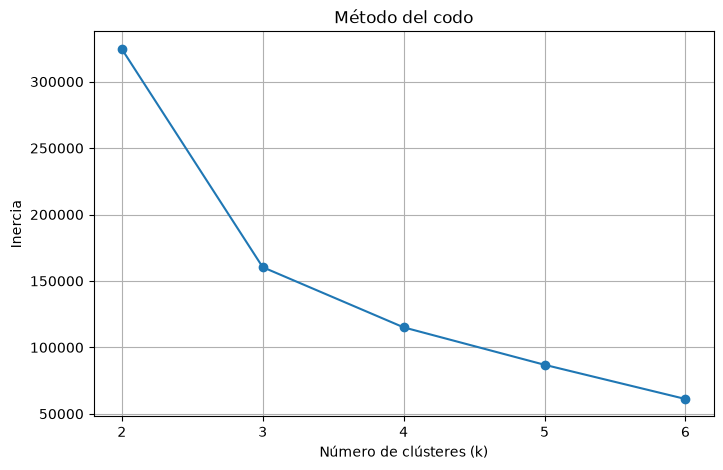

In [18]:
# 4. Gráfica del método del codo
plt.figure(figsize=(8, 5))
plt.plot(
    df_resultados["k"],
    df_resultados["Inercia"],
    marker="o"
)
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(range(2, 7))
plt.grid(True)
plt.show()


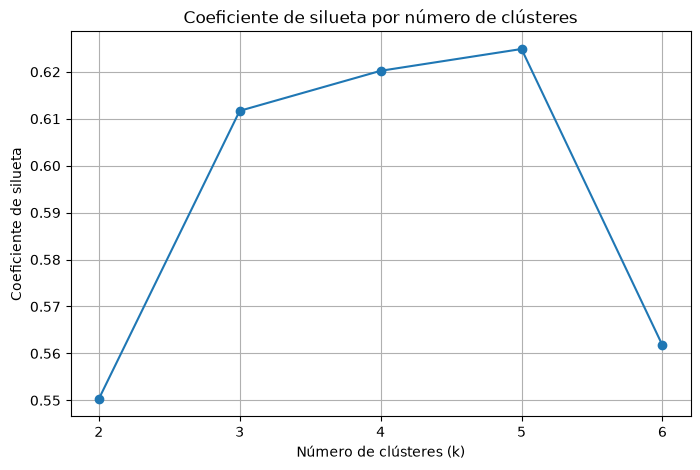

In [19]:
#coeficiente de silueta
plt.figure(figsize=(8, 5))
plt.plot(
    df_resultados["k"],
    df_resultados["Silueta"],
    marker="o"
)
plt.title("Coeficiente de silueta por número de clústeres")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(range(2, 7))
plt.grid(True)
plt.show()


## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`passenger_count`**, eje Y = **`trip_distance`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

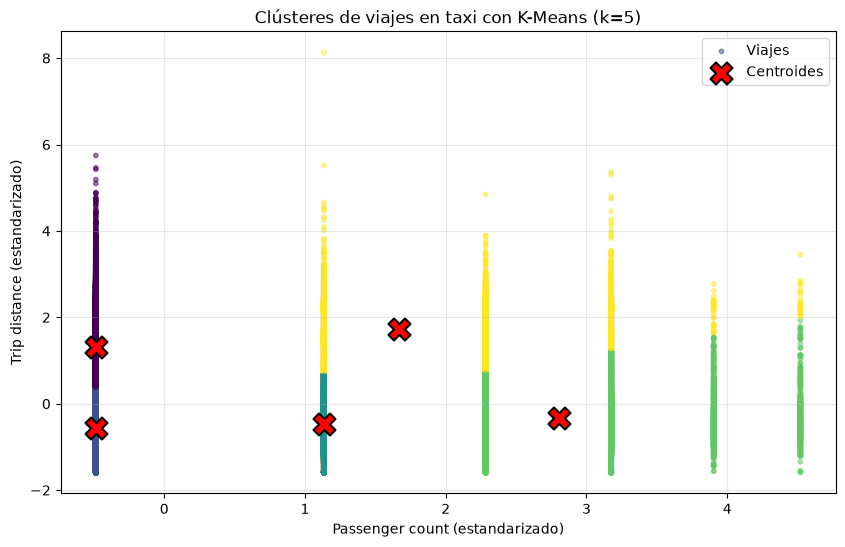

In [20]:
k_final = 5

kmeans_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

etiquetas = kmeans_final.fit_predict(X_escalado)

df_cash["cluster"] = etiquetas

centroides = kmeans_final.cluster_centers_


plt.figure(figsize=(10, 6))

plt.scatter(
    X_escalado["passenger_count"],
    X_escalado["trip_distance"],
    c=etiquetas,
    cmap="viridis",
    s=10,
    alpha=0.5,
    label="Viajes"
)

plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    linewidths=1.5,
    label="Centroides"
)

plt.title("Clústeres de viajes en taxi con K-Means (k=5)")
plt.xlabel("Passenger count (estandarizado)")
plt.ylabel("Trip distance (estandarizado)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `passenger_count`.
   - **Media y mediana** de `trip_distance`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: número de pasajeros y millas para la distancia.

**Evidencia:** tabla de estadísticos por clúster.

In [21]:
df_resultado = df_cash.copy()

df_resultado["cluster"] = etiquetas

tabla_clusters = df_resultado.groupby("cluster").agg(
    cantidad_viajes=("cluster", "count"),
    pasajeros_media=("passenger_count", "mean"),
    pasajeros_mediana=("passenger_count", "median"),
    distancia_media=("trip_distance", "mean"),
    distancia_mediana=("trip_distance", "median")
)

tabla_clusters = tabla_clusters.round(2)

print()
display(tabla_clusters)


,cantidad_viajes,pasajeros_media,pasajeros_mediana,distancia_media,distancia_mediana
cluster,,,,,
0,60035,1.0,1.0,9.54,7.95
1,160283,1.0,1.0,1.36,1.20
2,28514,2.0,2.0,1.58,1.31
3,16904,3.6,4.0,1.97,1.48
4,16349,2.5,2.0,13.14,11.51


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.


**Respuesta:**
Escogí el valr 5 ya que este obtuvo el coeficiente de silueta mas alto lo que indica una buena separación entre los grupos dandome así un buen equilibrio entre separación e interpretación de los grupos

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**
Cluster 0: Viajes largos individuales: tiene 60,035 viajes, con una media y mediana de 1 pasajero. La distancia media es de 9.54 millas y la mediana de 7.95 millas
Cluster 1: Viajes cortos individuales: es el grupo más numeroso, con 160,283 viajes. Tiene una media y mediana de 1 pasajero, y una distancia media de 1.36 millas y mediana de 1.20 millas
Cluster 2: Viajes cortos de dos pasajeros: contiene 28,514 viajes, con media y mediana de 2 pasajeros. La distancia media es de 1.58 millas y la mediana de 1.31 millas.
Cluster 3: Viajes cortos en grupos más grandes: contiene 16,904 viajes, con media de 3.6 pasajeros y mediana de 4. La distancia media es de 1.97 millas y la mediana de 1.48 millas
Cluster 4:Viajes largos con varios pasajeros: tiene 16,349 viajes, con media de 2.5 pasajeros y mediana de 2. Es el grupo con mayor distancia media, de 13.14 millas, y mediana de 11.51 millas


**Pregunta 3 — Análisis sencillo.** ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

**Respuesta:**
El cluster 0 es el que menor media de pasajeros tiene con una media de 1 y el 3 tiene una media de 3.6 aunque la media de distancia del cluster 0 es mayor que la del 3 lo que demuestra que los grupos con más pasajeros no necesariamente recorren mayores distancias


**Pregunta 4 — Análisis sencillo.** ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

**Respuesta:**
No, como comenté en la pregunta anterior el clúster 3 tiene la mayor media de pasajeros, con 3.6, pero su distancia media es de solo 1.97 millas. En cambio, el clúster 0 tiene una media de 1 pasajero y recorre 9.54 millas en promedio. El clúster 4 combina varios pasajeros con la mayor distancia media, de 13.14 millas. Por lo tanto, la cantidad de pasajeros no determina por sí sola la distancia del viaje.

---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**